In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [4]:
df = pd.read_csv("/Users/sourav/Desktop/Projects/Practise/credit-card-default-prediction/data/raw/UCI_Credit_Card.csv");
print("Dataset shape : ", df.shape)
display(df.head())

Dataset shape :  (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [9]:
# Check missing value
missing = df.isnull().sum()
print(missing[missing > 0])

missing_percantage = df.isnull().sum() * 100
display(
    missing_percantage.sort_values(
        ascending=False
    ).head(10)
)

Series([], dtype: int64)


ID           0
BILL_AMT2    0
PAY_AMT6     0
PAY_AMT5     0
PAY_AMT4     0
PAY_AMT3     0
PAY_AMT2     0
PAY_AMT1     0
BILL_AMT6    0
BILL_AMT5    0
dtype: int64

In [44]:
# Check duplicate records
print("Duplicate IDs : ", df["ID"].duplicated().sum())
print("Fully duplicated rows : ", df.duplicated().sum())

Duplicate IDs :  0
Fully duplicated rows :  0


In [45]:
# Rename columns for readability
df = df.rename(columns={
    "PAY_0" : "PAY_1",
    "default.payment.next.month" : "default"
})

print(df.columns.tolist())

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default']


In [46]:
# Investigate invalid category codes
# For example, education may contain values outside the main documented categories, 
# and marriage can contain a code of 0.
print("Education values:")
print(df["EDUCATION"].value_counts().sort_index())

print("\nMarraige value : ")
print(df["MARRIAGE"].value_counts().sort_index())

Education values:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

Marraige value : 
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [47]:
df["education_clean"] = df["EDUCATION"].where(
    df["EDUCATION"].isin([1,2,3]),
    4
)

df["marriage_clean"] = df["MARRIAGE"].where(
    df["MARRIAGE"].isin([1,2,3]),
    0
)

In [48]:
# Check repayment status values
# The documented repayment delay codes primarily run from -1 to 9, 
# but the dataset also contains -2 and 0. These codes require careful interpretation.
pay_columns = [
    "PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"
]
for col in pay_columns:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())


PAY_1
PAY_1
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

PAY_2
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

PAY_3
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

PAY_4
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64

PAY_5
PAY_5
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8        1
Name: count, dtype: int64

PAY_6
PAY_6
-2     4895
-1     5740
 0    16286
 2     2766
 3      184
 4       49
 5       13
 6       19
 7       46
 8        2
Name: count, dtype: int6

In [49]:
# Check numerical outliers
numeric_columns = [
    "LIMIT_BAL", "AGE", 
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", 
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]
display(
    df[numeric_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.00,964511.0
BILL_AMT2,30000.0,49179.075167,71173.768783,-69777.0,2984.75,21200.0,64006.25,983931.0
BILL_AMT3,30000.0,47013.154800,69349.387427,-157264.0,2666.25,20088.5,60164.75,1664089.0
BILL_AMT4,30000.0,43262.948967,64332.856134,-170000.0,2326.75,19052.0,54506.00,891586.0
BILL_AMT5,30000.0,40311.400967,60797.155770,-81334.0,1763.00,18104.5,50190.50,927171.0
BILL_AMT6,30000.0,38871.760400,59554.107537,-339603.0,1256.00,17071.0,49198.25,961664.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.00,873552.0
PAY_AMT2,30000.0,5921.163500,23040.870402,0.0,833.00,2009.0,5000.00,1684259.0


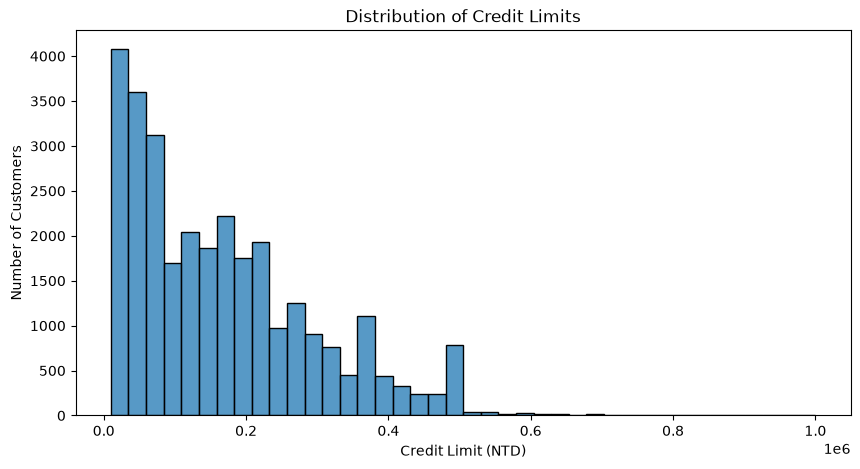

In [62]:
# Plot the credit limit distribution
plt.figure(figsize=(10,5))

sns.histplot(
    df["LIMIT_BAL"],
    bins=40
)

plt.title("Distribution of Credit Limits")
plt.xlabel("Credit Limit (NTD)")
plt.ylabel("Number of Customers")

plt.show()

In [69]:
# Check for impossible values
print("Non-positive ages: ", (df["AGE"] <= 0).sum())

print("Non-positive credit limits: ", (df["LIMIT_BAL"] <= 0).sum())

print("Invalid target values: ", (~df["default"].isin([0,1])).sum())

print("Negative payment amounts: ", (df[
    ["PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"]
] < 0).sum())

Non-positive ages:  0
Non-positive credit limits:  0
Invalid target values:  0
Negative payment amounts:  PAY_AMT1    0
PAY_AMT2    0
PAY_AMT3    0
PAY_AMT4    0
PAY_AMT5    0
PAY_AMT6    0
dtype: int64


In [82]:
from pathlib import Path

df_clean = df.drop(
    columns=["EDUCATION", "MARRIAGE"]
).rename(columns={
    "education_clean": "EDUCATION",
    "marriage_clean": "MARRIAGE"
})

Path("../data/processed/UCI_Credit_Card.csv").mkdir(
    parents=True,
    exist_ok=True
)

df_clean.to_csv(
    "../data/processed/credit_card_cleaned.csv",
    index=False
)

print("Cleaned dataset saved!")
print("Shape:", df_clean.shape)

# Notice that:
# - The original EDUCATION and MARRIAGE columns have been removed.
# - Their cleaned versions have been renamed to EDUCATION and MARRIAGE.
# - The resulting dataset contains only the cleaned versions.

Cleaned dataset saved!
Shape: (30000, 25)


In [83]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               30000 non-null  int64  
 1   LIMIT_BAL        30000 non-null  float64
 2   SEX              30000 non-null  int64  
 3   EDUCATION        30000 non-null  int64  
 4   MARRIAGE         30000 non-null  int64  
 5   AGE              30000 non-null  int64  
 6   PAY_1            30000 non-null  int64  
 7   PAY_2            30000 non-null  int64  
 8   PAY_3            30000 non-null  int64  
 9   PAY_4            30000 non-null  int64  
 10  PAY_5            30000 non-null  int64  
 11  PAY_6            30000 non-null  int64  
 12  BILL_AMT1        30000 non-null  float64
 13  BILL_AMT2        30000 non-null  float64
 14  BILL_AMT3        30000 non-null  float64
 15  BILL_AMT4        30000 non-null  float64
 16  BILL_AMT5        30000 non-null  float64
 17  BILL_AMT6        30000 